SIB - Neural Networks
A Jupyter Notebook with examples of how to use the neural network layers.

In [5]:
# imports
import numpy as np
from si.neural_networks.layers import DenseLayer

In [6]:
# first layer of a network with 2 inputs and 3 neurons
x = np.array([[1, 2]])
W = np.array([[0.1, 0.2, -0.1],
              [0.3, -0.2, 0.4]])
b = np.array([[0.1, 0, -0.1]])
print(np.dot(x, W) + b)

[[ 0.8 -0.2  0.6]]


In [7]:
# shapes: (1, 2) x (2, 3) -> (1, 3)
print(x.shape, W.shape, b.shape, (np.dot(x, W) + b).shape)

(1, 2) (2, 3) (1, 3) (1, 3)


In [8]:
# network 2 -> 3 -> 1 with random weights in [-0.5, 0.5) and biases at zero
X = np.random.rand(5, 2)

W1 = np.random.rand(2, 3) - 0.5
b1 = np.zeros((1, 3))
W2 = np.random.rand(3, 1) - 0.5
b2 = np.zeros((1, 1))

hidden = np.dot(X, W1) + b1
output = np.dot(hidden, W2) + b2

print('X:', X.shape)
print('W1:', W1.shape, 'b1:', b1.shape)
print('hidden:', hidden.shape)
print('W2:', W2.shape, 'b2:', b2.shape)
print('output:', output.shape)

X: (5, 2)
W1: (2, 3) b1: (1, 3)
hidden: (5, 3)
W2: (3, 1) b2: (1, 1)
output: (5, 1)


In [9]:
# the same network with the DenseLayer class
layer1 = DenseLayer(3, (2,)).initialize()
layer2 = DenseLayer(1, layer1.output_shape()).initialize()

hidden = layer1.forward_propagation(X)
output = layer2.forward_propagation(hidden)
print(hidden.shape, output.shape)
print('Parameters:', layer1.parameters(), layer2.parameters())

(5, 3) (5, 1)
Parameters: 9 4


In [10]:
# gradient descent on L(w) = (w - 3)^2, starting at w = 0
import numpy as np


def gradient_descent(alpha, w=0.0, steps=4):
    for step in range(steps):
        gradient = 2 * (w - 3)
        w = w - alpha * gradient
        print(step, round(gradient, 3), round(w, 3))


gradient_descent(0.1)

0 -6.0 0.6
1 -4.8 1.08
2 -3.84 1.464
3 -3.072 1.771


In [11]:
# with a learning rate that is too high, the training diverges
gradient_descent(1.5)

0 -6.0 9.0
1 12.0 -9.0
2 -24.0 27.0
3 48.0 -45.0


In [13]:
# one training step by hand (2 -> 3 -> 1, no activations): forward
x = np.array([[1, 2]])
W1 = np.array([[0.1, 0.2, -0.1],
               [0.3, -0.2, 0.4]])
b1 = np.array([[0.1, 0, -0.1]])
W2 = np.array([[0.2], [-0.3], [0.1]])
b2 = np.zeros((1, 1))
y, alpha = 1, 0.1

h = np.dot(x, W1) + b1
y_hat = np.dot(h, W2) + b2
print('h:', h)
print('y_hat:', y_hat, 'loss:', (y - y_hat) ** 2)

h: [[ 0.8 -0.2  0.6]]
y_hat: [[0.28]] loss: [[0.5184]]


In [14]:
# gradients (backward propagation)
dE_dyhat = 2 * (y_hat - y)
dE_dW2 = np.dot(h.T, dE_dyhat)
dE_db2 = dE_dyhat
dE_dh = np.dot(dE_dyhat, W2.T)
dE_dW1 = np.dot(x.T, dE_dh)
dE_db1 = dE_dh
print('dE/dy_hat:', dE_dyhat)
print('dE/dW2:', dE_dW2.T)
print('dE/db2:', dE_db2)
print('dE/dh:', dE_dh)

dE/dy_hat: [[-1.44]]
dE/dW2: [[-1.152  0.288 -0.864]]
dE/db2: [[-1.44]]
dE/dh: [[-0.288  0.432 -0.144]]


In [15]:
# update the weights and the biases, and forward again: did the loss go down?
W2 = W2 - alpha * dE_dW2
b2 = b2 - alpha * dE_db2
W1 = W1 - alpha * dE_dW1
b1 = b1 - alpha * dE_db1

h = np.dot(x, W1) + b1
y_hat = np.dot(h, W2) + b2
print('y_hat:', y_hat, 'loss:', (y - y_hat) ** 2)

y_hat: [[0.72955648]] loss: [[0.0731397]]


In [16]:
# imports
from si.neural_networks.layers import DenseLayer, Dropout
from si.neural_networks.activation import (SigmoidActivation, ReLUActivation, TanhActivation, SoftmaxActivation)

In [17]:
# optimizer that does not change the weights (it only records the gradient) and a mse
class NoUpdate:
    def update(self, w, grad):
        self.grad = grad
        return w


mse = lambda Y, P: np.mean((Y - P) ** 2)
mse_derivative = lambda Y, P: 2 * (P - Y) / Y.size

In [18]:
# gradient check of the backward propagation of the dense layer
np.random.seed(0)
X, Y = np.random.rand(4, 3), np.random.rand(4, 2)
layer = DenseLayer(2, (3,)).initialize(NoUpdate())
out = layer.forward_propagation(X, training=True)

layer.backward_propagation(mse_derivative(Y, out))
analytic = layer.w_opt.grad
numeric = np.zeros_like(layer.weights)
eps = 1e-6
for i in range(3):
    for j in range(2):
        layer.weights[i, j] += eps
        p1 = mse(Y, layer.forward_propagation(X, True))
        layer.weights[i, j] -= 2 * eps
        p1m = mse(Y, layer.forward_propagation(X, True))
        layer.weights[i, j] += eps
        numeric[i, j] = (p1 - p1m) / (2 * eps)

print(np.abs(numeric - analytic).max())

1.513400516017782e-11


In [20]:
# check the derivatives of the activation layers
x, eps = np.array([-2.5, 1.2, 0.3, 0.4, 1.1, 2.7]), 1e-6
for act in [SigmoidActivation(), ReLUActivation(), TanhActivation()]:
    num = (act.activation_function(x + eps) - act.activation_function(x - eps)) / (2 * eps)
    print(act.layer_name(), np.abs(num - act.derivative(x)).max())

SigmoidActivation 7.954464864567967e-11
ReLUActivation 1.397779669787269e-10
TanhActivation 3.338995746560158e-11


In [21]:
# softmax: the outputs of each sample sum to 1, even with very large inputs
softmax = SoftmaxActivation()
scores = np.array([[1.0, 2.0, 3.0], [1000.0, 1001.0, 1002.0]])
probabilities = softmax.activation_function(scores)
print(probabilities)
print(probabilities.sum(axis=1))

[[0.09003057 0.24472847 0.66524096]
 [0.09003057 0.24472847 0.66524096]]
[1. 1.]


In [22]:
# dropout: training and inference modes
np.random.seed(0)
dropout = Dropout(probability=0.5)
x = np.ones((1000, 10))

output_training = dropout.forward_propagation(x, training=True)
print('fraction of zeros:', (output_training == 0).mean())
print('values of the output:', np.unique(output_training))

output_inference = dropout.forward_propagation(x, training=False)
print('inference unchanged:', np.array_equal(output_inference, x))

fraction of zeros: 0.5064
values of the output: [0. 2.]
inference unchanged: True


In [23]:
# dropout: the backward propagation multiplies the error by the mask
dropout.forward_propagation(x, training=True)
error = dropout.backward_propagation(np.ones_like(x))
print(np.array_equal(error, dropout.mask))

True


In [24]:
# imports for the plots
import matplotlib.pyplot as plt
from si.neural_networks.activation import LeakyReLUActivation

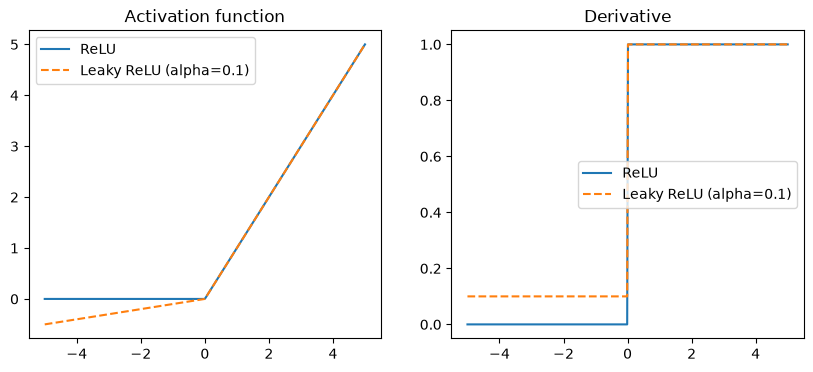

In [25]:
# relu and leaky relu: functions and derivatives
x = np.linspace(-5, 5, 400)
relu = ReLUActivation()
leaky_relu = LeakyReLUActivation(alpha=0.1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(x, relu.activation_function(x), label='ReLU')
axes[0].plot(x, leaky_relu.activation_function(x), '--', label='Leaky ReLU (alpha=0.1)')
axes[0].set_title('Activation function')
axes[0].legend()

axes[1].plot(x, relu.derivative(x), label='ReLU')
axes[1].plot(x, leaky_relu.derivative(x), '--', label='Leaky ReLU (alpha=0.1)')
axes[1].set_title('Derivative')
axes[1].legend()

plt.show()

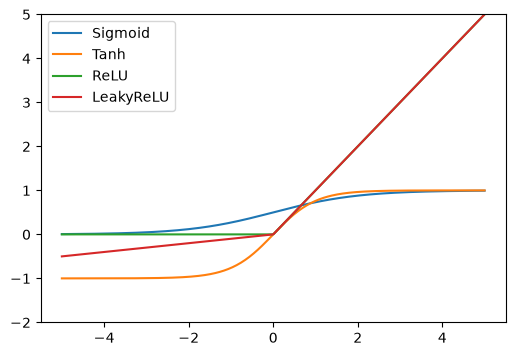

In [26]:
# all the activation functions in the same plot
plt.figure(figsize=(6, 4))
for act in (SigmoidActivation(), TanhActivation(), ReLUActivation(), LeakyReLUActivation(alpha=0.1)):
    plt.plot(x, act.activation_function(x), label=act.layer_name().replace('Activation', ''))
plt.ylim(-2, 5)
plt.legend()
plt.show()